## El experimento de 3 vías (por qué B sigue)

La tabla de arriba esconde tres condiciones distintas sobre las mismas 6.196 ventanas:

1. **B-limpio histórico** (4.251 / 2305.1): bundle congelado sobre dato impoluto.
2. **B-bajo-dropout** (4.247 / 2290.0): el mismo bundle, sin reentrenar, sobre el dato adaptado (MAR + ffill). Solo inferencia (`track_clase/evaluar_b_en_adaptada.py`, test `test_clase_b_robusto.py` verde). El ffill repara los huecos aislados: el campeón es insensible a este régimen.
3. **Híbrido-C** (4.338; media 4.314 ± 0.042): reentrenado bajo dropout. Ni siquiera toca al B con su `±`: no hay empate que desempatar, la puerta D11 no se supera.

Bundle C versionado en `track_clase/models/` con manifest propio. Sin re-freeze: adoptar C exigiría re-manifestar banda, reglas y caché sin ganancia métrica.


# 05 — Bundle C: ensemble sobre base adaptada (grano ventana)

Mismo protocolo que B sobre ventanas adaptadas (MAR T30 + ffill con medianas de fit-units, contrato 93 intacto, sin `fase_vuelo`). Grano **ventana**: la tabla SAA de filas (SVM 9.06, MLP 7.70) va aparte — prohibido el ranking mixto. La decisión se toma contra la puerta D11 en las mismas 6.196 ventanas test.

## El reparto: para qué sirve cada motor

- **Fit-units (2, 5, 10, 18, 20)**: aquí se ajusta todo (escalados, base polinómica, ridges, modelos base). Nada aguas abajo puede mirar otros motores.
- **Holdout 16**: early stopping del BiLSTM + ajuste del meta-aprendiz. Es el único motor que el meta ve, y por eso la validación honesta se mide fuera de él (OOF), no sobre él.
- **Test (11, 14, 15)**: se puntúa una sola vez. El test no elige arquitectura, solo comprueba que la validación decía la verdad.


## Por qué `cyc_norm` está en la base pero no en el meta

- `cyc_norm = cycle/100` es el proxy de desgaste acumulado (un vuelo = ~114 muestras con STRIDE=100, así que la ventana de 50 no cubre ni medio vuelo sin este canal).
- Vive en los modelos base: canal 19 del BiLSTM y feature 1/93 del LGBM. Ahí es una entrada legítima.
- **No** entra al meta-learner: medido, el meta ponía ~100% del peso en el reloj e ignoraba `p_lstm`/`p_lgb` (atajo). El stacking solo concilia las dos ramas (`Z = [p_lstm, p_lgb]`), y `beta`+EMA causal rematan en tiempo.

## Qué es cada pieza (I): los dos especialistas

- **BiLSTM**: lee la película temporal de la ventana (50 lecturas × 19 canales: los 18 escalados + `cyc_norm`). Dos capas bidireccionales de 64 unidades y cabeza de triple pooling: último paso (estado actual) + media (nivel de la trayectoria) + máximo (transitorio extremo).
- **LightGBM cuantil 0.35**: evalúa las estadísticas del residuo (las 93 del 04). Donde el BiLSTM ve inercia, el LGBM ve nivel.


## Qué es cada pieza (II): meta, beta, EMA

- **Meta-aprendiz**: se ajusta solo con `[p_lstm, p_lgb]` (predicción de cada rama en holdout). Sin `cyc_norm`: medido en B, el meta ponía ~100 % del peso en el reloj e ignoraba las dos ramas.
- **Beta**: cuánto de la opinión del meta reemplaza a la del BiLSTM (`p = p_lstm + beta·(p_meta − p_lstm)`), elegido fuera de fold. `beta = 1.00` significa meta puro: se dice en voz alta, no se esconde.
- **EMA5**: suavizado causal por motor en orden de ciclo. Evita que la alarma parpadee: la decisión de hoy no puede depender de la ventana de mañana.
- **Alcance honesto**: en clase decidimos sobre el punto (RMSE). La banda conformal se calibra y se guarda en el manifest del bundle, pero decidir sobre `L_inf` es mundo B, fuera de este track.


In [1]:
import pandas as pd
comp = pd.read_csv('../resultados/comparativa_bundle_c.csv')
print(comp.to_string(index=False))

                                Modelo  RMSE   MAE     R2  NASA_Score   grano
                 LGBM-C (cuantil 0.35) 7.067 5.545 0.8570      5731.3 ventana
                              BiLSTM-C 5.654 4.295 0.9084      3674.0 ventana
                       BiLSTM-C + EMA5 5.618 4.268 0.9096      3649.4 ventana
          Híbrido-C (beta=1.00) + EMA5 4.338 3.227 0.9461      2336.2 ventana
Híbrido-B histórico (bundle congelado) 4.251 3.183 0.9482      2305.1 ventana


## Real vs predicho + análisis por motor (bundle C, test)

 motor   RMSE  n_ventanas
    11 3.6328        3293
    14 8.5761         760
    15 2.8371        2143



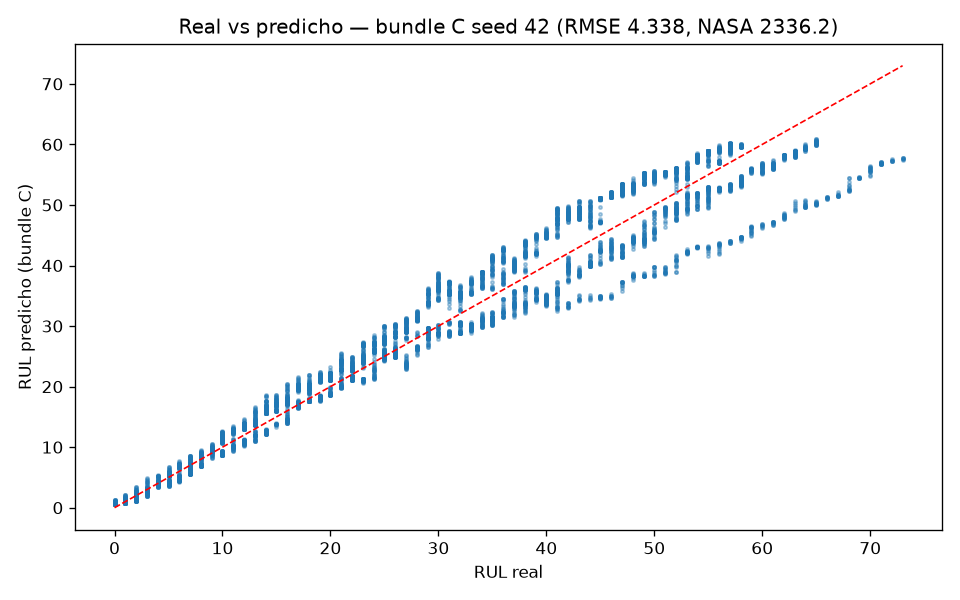


QUÉ VEO: el patrón por motor debe replicar al de B (U14 concentra el error).
CONCLUSIÓN: si se replica, el ventaneo honesto funciona también para el ensemble.


In [2]:
from IPython.display import Image, display
import pandas as pd
pm = pd.read_csv('../resultados/bundle_c_por_motor.csv')
print(pm.to_string(index=False))
print()
display(Image('../resultados/real_vs_predicho_bundle_c.png'))
print()
print('QUÉ VEO: el patrón por motor debe replicar al de B (U14 concentra el error).')
print('CONCLUSIÓN: si se replica, el ventaneo honesto funciona también para el ensemble.')

## Cierre — veredicto de la puerta D11

Se adopta C solo si `RMSE_C <= 4.251` **y** `NASA_C <= 2305.1` (B-histórico, mismas ventanas). Si no, C queda como experimento y B sigue en producción. SIN re-freeze en este change (requiere otra autorización).

In [3]:
import pandas as pd
comp = pd.read_csv('../resultados/comparativa_bundle_c.csv')
c = comp.loc[comp['Modelo'].str.startswith('Híbrido-C')].iloc[0]
ok_rmse = c['RMSE'] <= 4.251
ok_nasa = c['NASA_Score'] <= 2305.1
print(f"bundle C: RMSE {c['RMSE']:.3f} (<=4.251? {ok_rmse}) | "
      f"NASA {c['NASA_Score']:.1f} (<=2305.1? {ok_nasa})")
print('ADOPTAR (pendiente re-freeze autorizado)' if ok_rmse and ok_nasa
      else 'C queda como experimento, B sigue en producción')

bundle C: RMSE 4.338 (<=4.251? False) | NASA 2336.2 (<=2305.1? False)
C queda como experimento, B sigue en producción


## Multiseed (7, 123) — media ± desv

B publica sus titulares como media ± desv sobre [42, 7, 123]. Para comparar en la misma liga, este bloque repite el protocolo C en las seeds 7 y 123 reutilizando beta=1.00 (igual que el notebook 02 reutiliza BETA). Sin ablación: el diseño ya está decidido.

La ablación de `cyc_norm` la midió B; C la reutiliza sin re-medir (mismo contrato 93, mismo `run_seed`).


In [4]:
import sys; sys.path.insert(0, '..')
import numpy as np
import pandas as pd
from track_clase.train_ensemble_adaptado import (
    construir_raw_adaptado, FIT_UNITS, HOLDOUT_UNITS, TEST_UNITS)
from ds02_rul import HybridStackingEnsemble
from ds02_rul.metrics import evaluate_predictions
from ds02_rul.pipeline import run_seed
from ds02_rul.stacking import fit_meta_learners
raw = construir_raw_adaptado()
filas = []
for seed in (7, 123):
    out = run_seed(raw, seed=seed, fit_units=FIT_UNITS,
                   holdout_units=HOLDOUT_UNITS, test_units=TEST_UNITS,
                   window=50, step_train=3, step_test=2, epochs=22)
    Z = np.column_stack([out['p_lstm_hold'], out['p_lgb_hold']])
    ridge_s, lgbm_s = fit_meta_learners(
        Z, out['dev']['y'][out['hold_idx']], seed=seed)
    ens = HybridStackingEnsemble(
        bilstm_model=out['bilstm'], lgb_standalone=out['lgbm'],
        ridge_meta=ridge_s, lgb_meta=lgbm_s,
        residualizer=out['prep']['residualizer'],
        scaler=out['prep']['scaler'], scaler_w=out['prep']['scaler_w'],
        n_op=4, window_size=50, beta=1.00, ema_span=5)
    t = out['test']
    pe = ens.predict(t['X_raw'], t['meta']['cycle'].values,
                     t['meta']['unit'].values)
    m = evaluate_predictions(t['y'], pe, f'Híbrido-C seed {seed}')
    filas.append({'seed': seed, 'RMSE': m['RMSE'], 'MAE': m['MAE'],
                  'R2': m['R2'], 'NASA_Score': m['NASA_Score']})
    print(f"seed {seed}: RMSE {m['RMSE']:.3f} | NASA {m['NASA_Score']:.1f}")
ms = pd.DataFrame(filas)
ms.to_csv('../resultados/bundle_c_multiseed.csv', index=False)
print(ms.to_string(index=False))

seed 7: RMSE 4.334 | NASA 2324.8


seed 123: RMSE 4.369 | NASA 2371.9
 seed  RMSE   MAE     R2  NASA_Score
    7 4.334 3.213 0.9462      2324.8
  123 4.369 3.279 0.9453      2371.9


In [5]:
import numpy as np
import pandas as pd
base = pd.read_csv('../resultados/comparativa_bundle_c.csv')
ms = pd.read_csv('../resultados/bundle_c_multiseed.csv')
r42 = base.loc[base['Modelo'].str.startswith('Híbrido-C')].iloc[0]
rmse = [float(r42['RMSE'])] + ms['RMSE'].tolist()
nasa = [float(r42['NASA_Score'])] + ms['NASA_Score'].tolist()
print(f"C (42,7,123): RMSE {np.mean(rmse):.3f} +- {np.std(rmse, ddof=1):.3f} | "
      f"NASA {np.mean(nasa):.1f} +- {np.std(nasa, ddof=1):.1f}")
print('B histórico: RMSE 4.251 | NASA 2305.1 (media multiseed congelada)')
print('Veredicto: ' + ('ADOPTAR (pendiente re-freeze autorizado)'
      if np.mean(rmse) <= 4.251 and np.mean(nasa) <= 2305.1
      else 'C queda como experimento, B sigue en producción'))

C (42,7,123): RMSE 4.347 +- 0.019 | NASA 2344.3 +- 24.6
B histórico: RMSE 4.251 | NASA 2305.1 (media multiseed congelada)
Veredicto: C queda como experimento, B sigue en producción


## Tabla final: dos ligas, dos campeones

La comparativa completa vive en `resultados/tabla_final_clase.csv` (una fila por modelo, columna `grano`). Se lee, no se ordena mezclada: cada grano elige al suyo.


In [ ]:
import pandas as pd
tab = pd.read_csv('../resultados/tabla_final_clase.csv')
print(tab[['modelo','grano','rmse_test','mae_test','r2_test',
           'nasa_test','tiempo_s']].to_string(index=False))
print()
for grano in ('fila','ventana'):
    sub = tab[tab['grano']==grano].sort_values('rmse_test')
    print('campeon %s: %s (RMSE %.4f)' % (grano, sub.iloc[0]['modelo'],
          sub.iloc[0]['rmse_test']))
print()
print('Lectura: dos ligas separadas. En fila manda MLP-E1 (7.70); en ventana, '
      'el B congelado (4.251) sobre el C adaptado (4.314). Prohibido mezclarlas.')


                                modelo   grano  rmse_test  mae_test  r2_test  nasa_test  tiempo_s
                                   knn    fila    11.5573   10.0876   0.6287        NaN       5.1
                             regresion    fila    11.7053   10.4625   0.6192        NaN       3.4
                                    rf    fila    11.8065   10.6349   0.6126        NaN      48.0
                                   svm    fila     9.0591    7.9947   0.7719        NaN       1.5
                                   xgb    fila    11.0340    9.9098   0.6616        NaN       4.8
                              MLP-base    fila     7.7792    5.7886   0.8318        NaN      23.4
                      MLP-E1_capacidad    fila     7.7019    5.5724   0.8351        NaN      56.4
                         MLP-E2_reg_lr    fila     7.7211    5.8132   0.8343        NaN      19.6
                          MLP-E3_batch    fila     7.7641    5.8475   0.8324        NaN      27.2
                    